# Transfer Learning: ensinar uma rede a ver lavouras

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rglopesdf/miniaula-transfer-learning/blob/main/transfer_learning_lavouras.ipynb)

**Miniaula de Aprendizagem Profunda** · Prof. Msc. Rogério Gomes Lopes

**Problema.** Classificar recortes de imagens de satélite (cerca de 1 km × 1 km) em quatro classes:
`soja`, `milho`, `outras` culturas e `nao_ha` (sem lavoura). Temos apenas **600 imagens** de treino.

**Objetivo.** Comparar três formas de treinar a mesma arquitetura (ResNet-18) e decidir o que
reaproveitar e o que treinar numa rede pré-treinada:

| | Estratégia | O que é treinado |
|---|---|---|
| **A** | Do zero | a rede inteira, a partir de pesos aleatórios |
| **B** | Extração de características | só a nova camada final (`fc`) |
| **C** | Fine-tuning | a nova `fc` e o último bloco (`layer4`) |

**Como usar no Colab**

1. Ative a GPU: **Ambiente de execução → Alterar o tipo de ambiente → GPU (T4)**. Em CPU também funciona, só é mais lento.
2. Execute tudo: **Ambiente de execução → Executar tudo**.
3. As células com formulário têm **campos editáveis à direita**. Mude um valor e execute a célula de novo para ver o efeito.
   Para ver o código de uma célula recolhida, clique duas vezes no título dela.

## 1. Preparação

In [1]:
#@title Baixar os dados da aula
#@markdown Clona o repositório com as 1.000 imagens (cerca de 4 MB). No seu computador, com o repositório já baixado, não faz nada.
import os
REPO = "https://github.com/rglopesdf/miniaula-transfer-learning.git"
if not os.path.isdir("dados"):
    if not os.path.isdir("miniaula-transfer-learning"):
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 {REPO}
    if not os.path.isdir("miniaula-transfer-learning"):
        raise RuntimeError("Não foi possível baixar o repositório. Verifique se ele está público: " + REPO)
    %cd miniaula-transfer-learning
print("Pasta de trabalho:", os.getcwd())

Pasta de trabalho: /home/user/miniaula-transfer-learning


In [2]:
#@title Bibliotecas e semente aleatória
#@markdown A **semente** fixa os sorteios (pesos iniciais, ordem das imagens), para que o resultado se repita.
SEMENTE = 42  #@param {type:"integer"}

import json, random, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import resnet18

random.seed(SEMENTE); np.random.seed(SEMENTE); torch.manual_seed(SEMENTE)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cpu


## 2. Os dados

As imagens vêm do dataset público **HLS Multi-Temporal Crop Classification** (IBM/NASA, licença CC BY 4.0):
imagens Landsat/Sentinel-2 dos EUA em 2022, rotuladas pelo mapa oficial de culturas do USDA.
O script `scripts/montar_dataset.py` recortou janelas de 32×32 pixels (30 m por pixel) em que uma
única classe ocupa pelo menos 70% da área.

### Por que as cores parecem estranhas? A falsa-cor

O satélite mede faixas de luz invisíveis ao olho. Uma imagem tem só três canais, então escolhemos que banda vai em cada um:

| Canal da imagem | Banda do satélite | Por que ela ajuda |
|---|---|---|
| Vermelho | Infravermelho próximo (NIR) | A estrutura da folha reflete muito: vegetação viva fica **clara** |
| Verde | Infravermelho de ondas curtas (SWIR 1) | É absorvido pela água: separa planta úmida de solo seco e cidade |
| Azul | Vermelho visível | A clorofila absorve: vegetação viva fica **escura** |

### Como a rede espera receber as imagens

A ResNet-18 foi pré-treinada com fotos do ImageNet de **224×224 pixels**, com cada canal **normalizado** pela média e pelo
desvio padrão do ImageNet. Repetimos o mesmo preparo, porque os pesos foram calibrados para essa escala de entrada.
Os valores vêm da própria biblioteca: `ResNet18_Weights.IMAGENET1K_V1.transforms()`.

No treino, cada imagem pode ser **espelhada** na horizontal ou na vertical (aumento de dados): uma imagem vista de cima continua válida depois de espelhada.

In [3]:
#@title Carregar as imagens
#@markdown **Imagens usadas no treino:** a falsa-cor é o padrão. Experimente também a cor real (pergunta 7 do final).
IMAGENS = "falsa-cor"  #@param ["falsa-cor", "cor real"]
#@markdown **Tamanho do lote:** quantas imagens a rede vê antes de cada atualização dos pesos.
TAMANHO_DO_LOTE = 32  #@param [16, 32, 64] {type:"raw"}
#@markdown **Aumento de dados:** espelha as imagens de treino ao acaso.
AUMENTO_DE_DADOS = True  #@param {type:"boolean"}

MEDIA, DESVIO = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]     # estatísticas do ImageNet

passos_treino = [transforms.Resize(224)]
if AUMENTO_DE_DADOS:
    passos_treino += [transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip()]
passos_treino += [transforms.ToTensor(), transforms.Normalize(MEDIA, DESVIO)]
t_treino = transforms.Compose(passos_treino)
t_teste = transforms.Compose([transforms.Resize(224), transforms.ToTensor(), transforms.Normalize(MEDIA, DESVIO)])

PASTA = "dados" if IMAGENS == "falsa-cor" else "dados_cor_real"
treino = datasets.ImageFolder(f"{PASTA}/treino", t_treino)
teste = datasets.ImageFolder(f"{PASTA}/teste", t_teste)
classes = treino.classes
print("Imagens:", IMAGENS, "| Classes:", classes)
print("Treino:", len(treino), "imagens | Teste:", len(teste), "imagens")

g = torch.Generator().manual_seed(SEMENTE)
dl_treino = DataLoader(treino, batch_size=TAMANHO_DO_LOTE, shuffle=True, generator=g, num_workers=2)
dl_teste = DataLoader(teste, batch_size=64, num_workers=2)

Imagens: falsa-cor | Classes: ['milho', 'nao_ha', 'outras', 'soja']
Treino: 600 imagens | Teste: 400 imagens


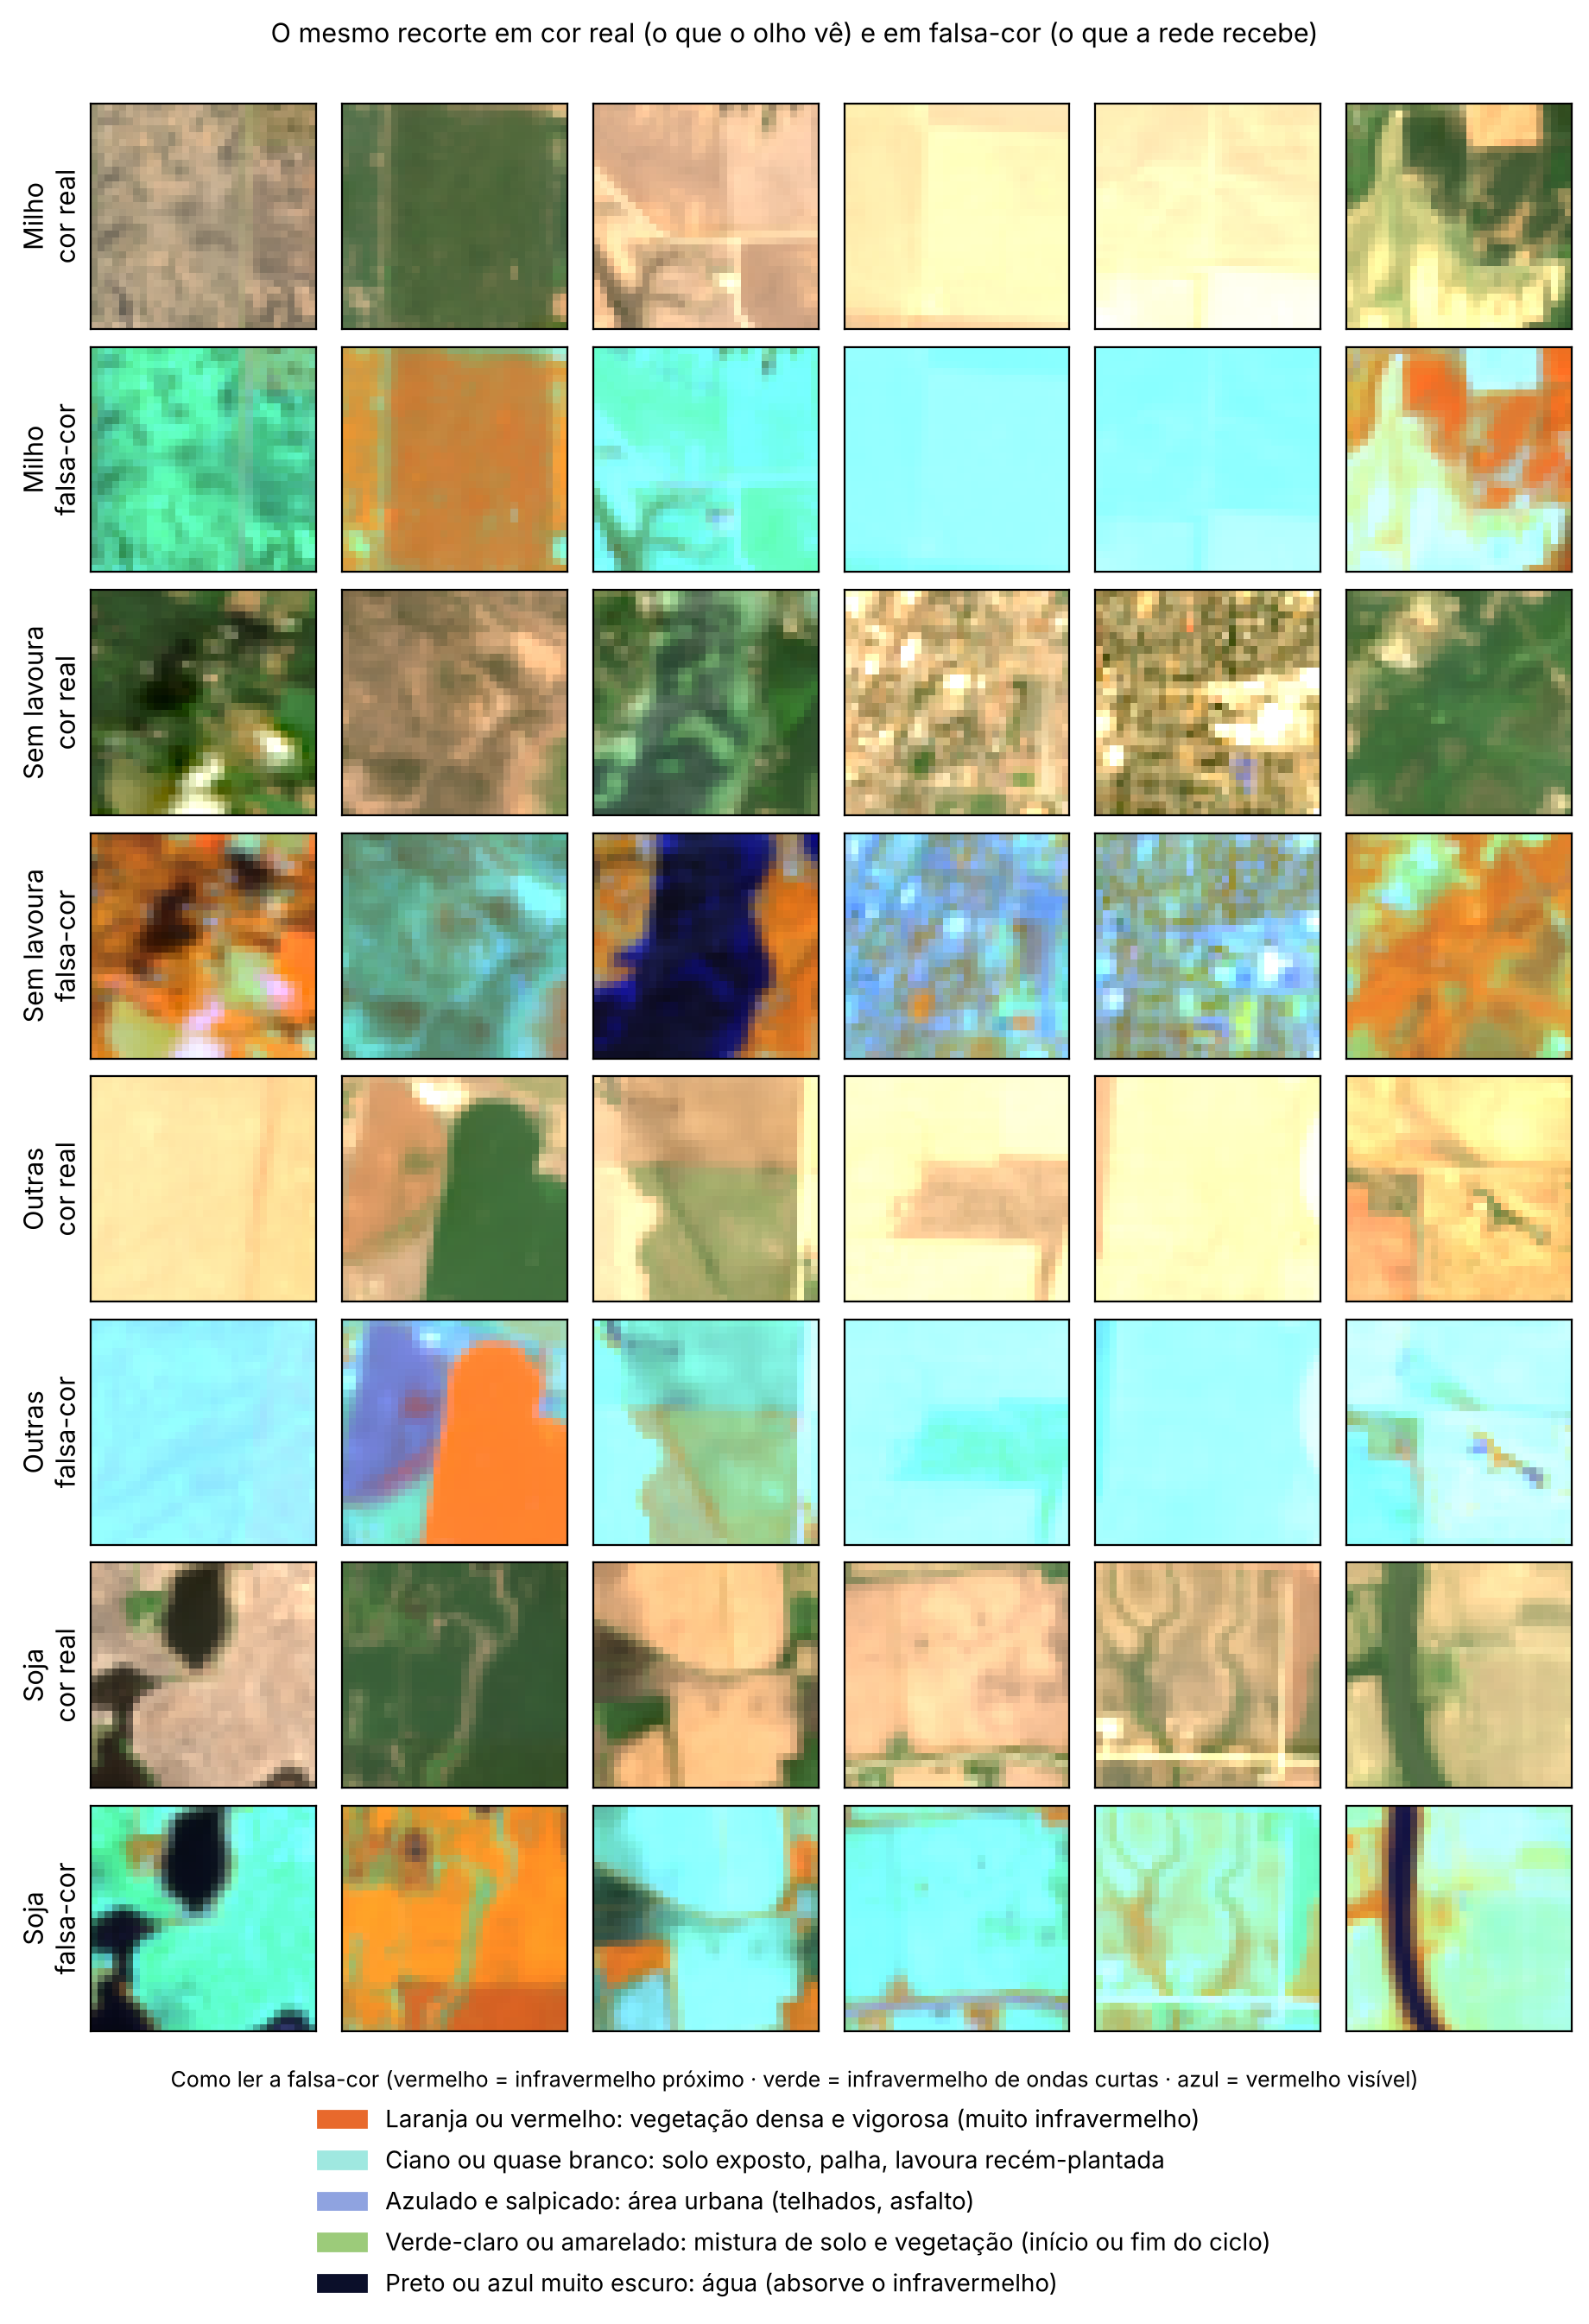

In [4]:
#@title Ver exemplos de cada classe: cor real e falsa-cor
#@markdown Cada quadrado é um recorte de cerca de 1 km × 1 km. Para cada classe, a linha de cima mostra o que o olho veria
#@markdown (cor real) e a de baixo, o mesmo recorte em falsa-cor, como a rede recebe.
EXEMPLOS_POR_CLASSE = 6  #@param {type:"slider", min:3, max:10, step:1}

nomes = {"milho": "Milho", "nao_ha": "Sem lavoura", "outras": "Outras", "soja": "Soja"}
base = datasets.ImageFolder("dados/treino")
fig, eixos = plt.subplots(8, EXEMPLOS_POR_CLASSE, figsize=(1.55 * EXEMPLOS_POR_CLASSE, 13.6))
for i, c in enumerate(base.classes):
    idx = [k for k, (_, y) in enumerate(base.samples) if y == i]
    passo = max(1, len(idx) // EXEMPLOS_POR_CLASSE)
    for j, k in enumerate(idx[::passo][:EXEMPLOS_POR_CLASSE]):
        falsa = base.samples[k][0]
        real = falsa.replace("dados", "dados_cor_real", 1)
        for linha, arquivo in [(2 * i, real), (2 * i + 1, falsa)]:
            eixos[linha, j].imshow(plt.imread(arquivo), interpolation="nearest")
            eixos[linha, j].set_xticks([]); eixos[linha, j].set_yticks([])
    eixos[2 * i, 0].set_ylabel(f"{nomes[c]}\ncor real", fontsize=11)
    eixos[2 * i + 1, 0].set_ylabel(f"{nomes[c]}\nfalsa-cor", fontsize=11)

legenda = [
    Patch(color="#E8692C", label="Laranja ou vermelho: vegetação densa e vigorosa (muito infravermelho)"),
    Patch(color="#9FE8E0", label="Ciano ou quase branco: solo exposto, palha, lavoura recém-plantada"),
    Patch(color="#8FA3E0", label="Azulado e salpicado: área urbana (telhados, asfalto)"),
    Patch(color="#9CCB7A", label="Verde-claro ou amarelado: mistura de solo e vegetação (início ou fim do ciclo)"),
    Patch(color="#0B0F2A", label="Preto ou azul muito escuro: água (absorve o infravermelho)"),
]
fig.legend(handles=legenda, loc="lower center", ncol=1, fontsize=10, frameon=False, bbox_to_anchor=(0.5, 0.0),
           title="Como ler a falsa-cor (vermelho = infravermelho próximo · verde = infravermelho de ondas curtas · azul = vermelho visível)",
           title_fontsize=9)
plt.suptitle("O mesmo recorte em cor real (o que o olho vê) e em falsa-cor (o que a rede recebe)", fontsize=11)
plt.tight_layout(rect=(0, 0.11, 1, 0.98)); plt.show()

**Compare as duas linhas de cada classe.** Na cor real, solo exposto aparece bege, lavoura desenvolvida aparece verde-escura
e a cidade aparece em quarteirões. Na falsa-cor, a vegetação viva salta em laranja, porque reflete muito infravermelho, que o olho não vê.

A legenda descreve tendências gerais, não regras: a cor de uma lavoura muda com a data da imagem.
Soja e milho às vezes aparecem com dossel fechado (verde-escuro na cor real, laranja na falsa-cor) e às vezes com muito solo à mostra.
Por isso as duas classes se confundem quando usamos **uma única data**; na prática, usa-se a série de imagens ao longo da safra.


## 3. Funções de treino e avaliação

Um detalhe importante: as camadas **congeladas** ficam em modo de avaliação (`eval`), para que a
normalização em lote (*batch normalization*) continue usando as estatísticas aprendidas no pré-treino.

In [5]:
#@title Funções de treino e avaliação
#@markdown **Épocas:** quantas vezes a rede percorre as 600 imagens de treino. Vale para os três experimentos.
EPOCAS = 12  #@param {type:"slider", min:1, max:30, step:1}

def modo_treino(model):
    model.train()
    for bloco in model.children():                       # blocos sem nenhum parâmetro treinável
        if not any(p.requires_grad for p in bloco.parameters()):
            bloco.eval()                                 # ficam "congelados" de verdade

def avaliar(model):
    model.eval()
    certos, previsoes = 0, []
    with torch.no_grad():
        for x, y in dl_teste:
            p = model(x.to(device)).argmax(1).cpu()
            certos += (p == y).sum().item(); previsoes += p.tolist()
    return certos / len(teste), previsoes

def treinar(model, otimizador, epocas):
    model.to(device)
    perda_fn = nn.CrossEntropyLoss()
    inicio = time.time()
    for ep in range(1, epocas + 1):
        modo_treino(model)
        soma, certos = 0.0, 0
        for x, y in dl_treino:
            x, y = x.to(device), y.to(device)
            saida = model(x)
            perda = perda_fn(saida, y)
            otimizador.zero_grad(); perda.backward(); otimizador.step()
            soma += perda.item() * len(y); certos += (saida.argmax(1) == y).sum().item()
        print(f"época {ep:2d} | perda {soma / len(treino):.3f} | acurácia no treino {certos / len(treino):.1%}")
    acc, previsoes = avaliar(model)
    n_treinaveis = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\nAcurácia no TESTE: {acc:.1%} | parâmetros treinados: {n_treinaveis:,} | tempo: {time.time() - inicio:.0f} s")
    return dict(acuracia_teste=acc, acuracia_treino=certos / len(treino), parametros_treinados=n_treinaveis,
                tempo_s=round(time.time() - inicio), previsoes=previsoes)

resultados = {}
print("Funções prontas. Épocas por experimento:", EPOCAS)

Funções prontas. Épocas por experimento: 12


## 4. Experimento A: treinar do zero

A mesma ResNet-18, mas com pesos aleatórios. Todos os 11,2 milhões de parâmetros são treinados com 600 imagens.

In [6]:
#@title Experimento A: do zero
TAXA_DE_APRENDIZADO = 0.001  #@param {type:"number"}

torch.manual_seed(SEMENTE)
model = resnet18(weights=None)                      # pesos aleatórios
model.fc = nn.Linear(512, 4)

otimizador = torch.optim.Adam(model.parameters(), lr=TAXA_DE_APRENDIZADO)
resultados["A. Do zero"] = treinar(model, otimizador, EPOCAS)

época  1 | perda 1.446 | acurácia no treino 39.0%


época  2 | perda 1.217 | acurácia no treino 46.5%


época  3 | perda 1.114 | acurácia no treino 50.2%


época  4 | perda 1.063 | acurácia no treino 50.8%


época  5 | perda 1.105 | acurácia no treino 50.5%


época  6 | perda 1.018 | acurácia no treino 56.2%


... (3 outputs left out)

época 10 | perda 0.997 | acurácia no treino 56.3%


época 11 | perda 0.997 | acurácia no treino 57.8%


época 12 | perda 0.977 | acurácia no treino 56.3%



Acurácia no TESTE: 60.5% | parâmetros treinados: 11,178,564 | tempo: 333 s


## 5. Experimento B: extração de características

Carregamos a ResNet-18 **pré-treinada no ImageNet**, congelamos tudo e trocamos a camada final.
Só a nova `fc` é treinada: 512 × 4 pesos + 4 vieses = **2.052 parâmetros**.

In [7]:
#@title Experimento B: extração de características
TAXA_DE_APRENDIZADO = 0.001  #@param {type:"number"}

torch.manual_seed(SEMENTE)
model = resnet18(weights="IMAGENET1K_V1")           # pré-treinada

for p in model.parameters():
    p.requires_grad = False                         # congela tudo
model.fc = nn.Linear(512, 4)                        # nova cabeça (já nasce treinável)

otimizador = torch.optim.Adam(model.fc.parameters(), lr=TAXA_DE_APRENDIZADO)
resultados["B. Extração de características"] = treinar(model, otimizador, EPOCAS)

época  1 | perda 1.428 | acurácia no treino 28.0%


época  2 | perda 1.234 | acurácia no treino 45.3%


época  3 | perda 1.124 | acurácia no treino 52.2%


época  4 | perda 1.054 | acurácia no treino 58.2%


época  5 | perda 1.017 | acurácia no treino 58.8%


época  6 | perda 0.977 | acurácia no treino 59.8%


... (3 outputs left out)

época 10 | perda 0.898 | acurácia no treino 64.2%


época 11 | perda 0.871 | acurácia no treino 66.7%


época 12 | perda 0.859 | acurácia no treino 68.2%



Acurácia no TESTE: 63.7% | parâmetros treinados: 2,052 | tempo: 106 s


## 6. Experimento C: fine-tuning

Igual ao experimento B, mas **descongelamos** um ou mais blocos do final da rede. O padrão é só o `layer4`,
o bloco mais especializado no ImageNet. Os blocos descongelados recebem uma taxa de aprendizado menor que a da nova `fc`,
para ajustar sem destruir o que já foi aprendido.

In [8]:
#@title Experimento C: fine-tuning
#@markdown **Blocos a descongelar:** experimente também `layer3 + layer4` (pergunta 5 do final).
BLOCOS_DESCONGELADOS = "layer4"  #@param ["layer4", "layer3 + layer4"]
TAXA_DA_NOVA_FC = 0.001  #@param {type:"number"}
TAXA_DOS_BLOCOS = 0.0001  #@param {type:"number"}

torch.manual_seed(SEMENTE)
model = resnet18(weights="IMAGENET1K_V1")

for p in model.parameters():
    p.requires_grad = False
model.fc = nn.Linear(512, 4)

blocos = [getattr(model, nome.strip()) for nome in BLOCOS_DESCONGELADOS.split("+")]
for bloco in blocos:                                # fine-tuning
    for p in bloco.parameters():
        p.requires_grad = True

otimizador = torch.optim.Adam([
    {"params": model.fc.parameters(), "lr": TAXA_DA_NOVA_FC},
    {"params": [p for b in blocos for p in b.parameters()], "lr": TAXA_DOS_BLOCOS},   # taxa baixa no que já foi aprendido
])
resultados[f"C. Fine-tuning ({BLOCOS_DESCONGELADOS})"] = treinar(model, otimizador, EPOCAS)

época  1 | perda 1.131 | acurácia no treino 50.3%


época  2 | perda 0.768 | acurácia no treino 69.8%


época  3 | perda 0.562 | acurácia no treino 79.3%


época  4 | perda 0.375 | acurácia no treino 89.3%


época  5 | perda 0.330 | acurácia no treino 89.7%


época  6 | perda 0.246 | acurácia no treino 91.5%


... (3 outputs left out)

época 10 | perda 0.076 | acurácia no treino 98.3%


época 11 | perda 0.076 | acurácia no treino 98.3%


época 12 | perda 0.064 | acurácia no treino 98.0%



Acurácia no TESTE: 65.2% | parâmetros treinados: 8,395,780 | tempo: 134 s


## 7. Comparação

Estratégia                             Teste  Treino  Parâm. treinados   Tempo
A. Do zero                             60.5%   56.3%        11,178,564    333s
B. Extração de características         63.7%   68.2%             2,052    106s
C. Fine-tuning (layer4)                65.2%   98.0%         8,395,780    134s


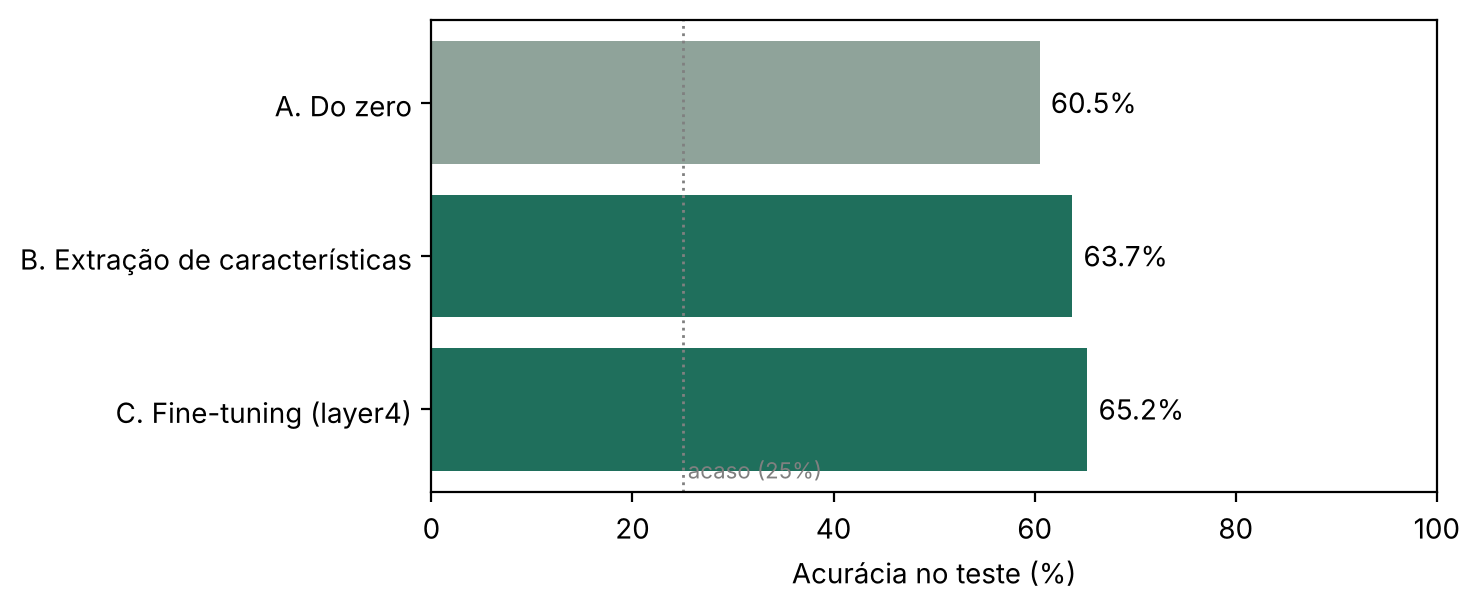

In [9]:
#@title Tabela e gráfico dos resultados
print(f"{'Estratégia':36s} {'Teste':>7s} {'Treino':>7s} {'Parâm. treinados':>17s} {'Tempo':>7s}")
for nome, r in resultados.items():
    print(f"{nome:36s} {r['acuracia_teste']:7.1%} {r['acuracia_treino']:7.1%} {r['parametros_treinados']:17,d} {r['tempo_s']:6d}s")

plt.figure(figsize=(7.5, 0.9 + 0.75 * len(resultados)))
nomes_r = list(resultados); vals = [resultados[n]["acuracia_teste"] * 100 for n in nomes_r]
cores = ["#8FA39A" if n.startswith("A") else "#1F6F5C" for n in nomes_r]
barras = plt.barh(nomes_r[::-1], vals[::-1], color=cores[::-1])
plt.bar_label(barras, fmt="%.1f%%", padding=4); plt.xlim(0, 100)
plt.axvline(25, color="gray", ls=":", lw=1); plt.text(25.5, -0.45, "acaso (25%)", color="gray", fontsize=8)
plt.xlabel("Acurácia no teste (%)"); plt.tight_layout(); plt.show()

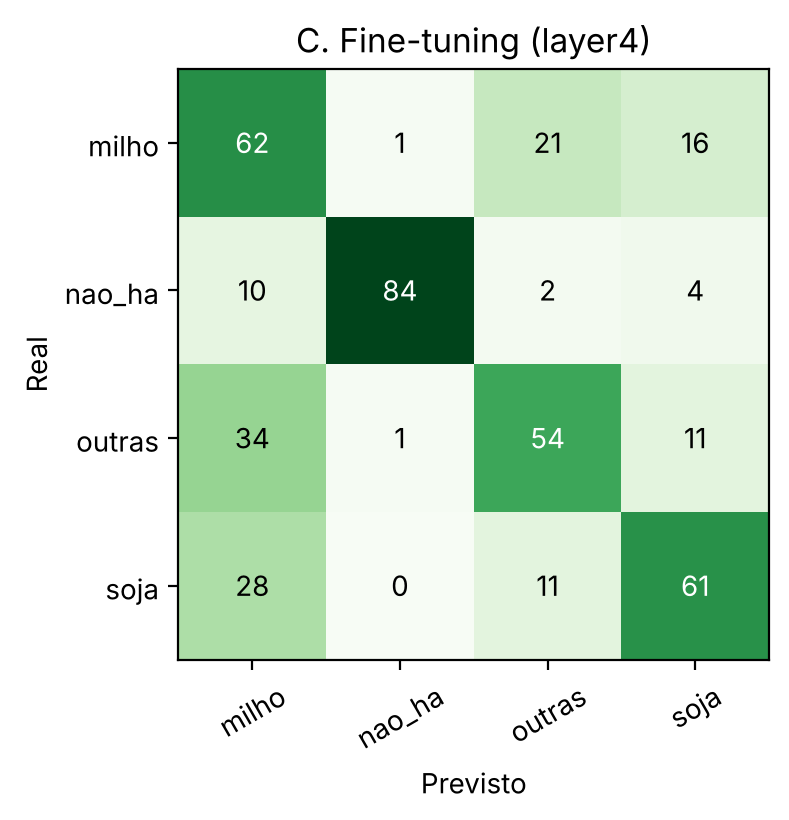

In [10]:
#@title Matriz de confusão: onde o modelo erra?
#@markdown Mostra o melhor modelo entre os que foram treinados.
melhor = max(resultados, key=lambda n: resultados[n]["acuracia_teste"])
y_real = [y for _, y in teste.samples]
M = np.zeros((4, 4), dtype=int)
for r, p in zip(y_real, resultados[melhor]["previsoes"]):
    M[r, p] += 1

plt.figure(figsize=(4.8, 4.2))
plt.imshow(M, cmap="Greens")
for i in range(4):
    for j in range(4):
        plt.text(j, i, M[i, j], ha="center", va="center", color="white" if M[i, j] > M.max() / 2 else "black")
plt.xticks(range(4), classes, rotation=30); plt.yticks(range(4), classes)
plt.xlabel("Previsto"); plt.ylabel("Real"); plt.title(melhor); plt.tight_layout(); plt.show()

json.dump({n: {k: v for k, v in r.items() if k != "previsoes"} for n, r in resultados.items()} |
          {"matriz_confusao": {"modelo": melhor, "classes": classes, "matriz": M.tolist()}, "epocas": EPOCAS, "dispositivo": device},
          open("resultados.json", "w"), ensure_ascii=False, indent=2)

## 8. Para pensar

1. Compare a acurácia no **treino** e no **teste** do experimento C e depois do experimento B. O que a diferença entre os dois indica?
2. O experimento B treina 2.052 parâmetros e o A treina mais de 11 milhões. Como o B consegue um resultado igual ou melhor, em menos tempo?
3. Olhe a matriz de confusão: quais classes o modelo mais confunde? Use a legenda de cores da seção 2 para explicar por quê.
4. Imagens de satélite em falsa-cor são muito diferentes das fotos do ImageNet. Em qual quadrante da matriz
   de decisão (quantidade de dados × semelhança de domínio) este problema está? O resultado confirma a recomendação?
5. **Experimente:** no experimento C, escolha `layer3 + layer4` e execute a célula de novo. O resultado melhora ou piora? Por quê?
6. **Experimente:** desligue o aumento de dados na seção 2 e treine de novo. O que acontece com o sobreajuste?
7. **Experimente:** na seção 2, troque as imagens para `cor real` e execute tudo de novo. A acurácia sobe ou cai? Por que a falsa-cor pode ajudar a separar lavouras?

**Cuidado ao comparar.** Com 400 imagens de teste, a margem de erro de cada acurácia é de cerca de 5 pontos percentuais.
Diferenças menores que isso entre dois experimentos não permitem dizer qual é o melhor.

**Observação metodológica.** O número de épocas foi fixado antes dos experimentos e o conjunto de teste foi
usado uma única vez, ao final de cada treino. Num projeto real, separe também um conjunto de **validação**
para escolher hiperparâmetros.

### Referências

**Leitura principal**

- GOODFELLOW, I.; BENGIO, Y.; COURVILLE, A. *Deep Learning*. MIT Press, 2016. Seção 15.2 (Transfer Learning and Domain Adaptation). Disponível gratuitamente em: https://www.deeplearningbook.org

**Leituras complementares**

- YOSINSKI, J. et al. How transferable are features in deep neural networks? *NeurIPS*, 2014.
- LECUN, Y.; BENGIO, Y.; HINTON, G. Deep learning. *Nature*, v. 521, p. 436-444, 2015.
- Em português: [Deep Learning Book](https://www.deeplearningbook.com.br/indice/) (Data Science Academy), capítulos 40 a 43 (redes convolucionais) e 77 (seção Transfer Learning).

**Dados:** CECIL, M. et al. *HLS Multi Temporal Crop Classification*. 2023. DOI 10.57967/hf/0955 (licença CC BY 4.0).


---

**Declaração de uso de IA.** Este material foi preparado com apoio de IA generativa (Claude, da Anthropic) na elaboração dos slides, do código e da atividade. O professor definiu o conteúdo, revisou todo o material e é o responsável pelas informações apresentadas.
